# Proyecto final — Emisiones de CO₂ per cápita
## Notebook 2: Visualización y análisis exploratorio

**Curso:** Ciencia de Datos — Actividad 4: Proyecto final
**Institución:** Fundación Universitaria Agraria de Colombia (UNIAGRARIA)
**Responsable de este notebook:** José Alejandro Ochoa (GitHub: `Jos38a`)
**Equipo:** Juan Felipe Castañeda Rodríguez · José Alejandro Ochoa · Ricardo José Díaz

---

Este notebook usa los datos limpios del **Notebook 1** (`data/co2_paises_limpio.csv`, `data/co2_mundo.csv` y `data/co2_grupos_ingreso.csv`) para explorar las ideas centrales de la sección **"Per capita CO₂ emissions"** del artículo de Our World in Data:

1. ¿Cómo han evolucionado las emisiones globales, en total y por persona?
2. ¿Qué tan desiguales son las emisiones per cápita entre países y grupos de ingreso?
3. ¿Qué relación hay entre el ingreso de un país y sus emisiones por persona?

Se toma **2024** como año de referencia, porque es el año más reciente con datos consolidados (los de 2025 son una proyección preliminar del Global Carbon Project).

## 1. Preparación

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

paises = pd.read_csv("../data/co2_paises_limpio.csv")
mundo = pd.read_csv("../data/co2_mundo.csv")
grupos = pd.read_csv("../data/co2_grupos_ingreso.csv")

# Estilo común de las gráficas: colores consistentes y ejes discretos
AZUL, NARANJA, VERDE, AMARILLO, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a8a85"
TEXTO, TEXTO_2, REJILLA = "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({
    "figure.figsize": (10, 5), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": REJILLA, "axes.labelcolor": TEXTO_2,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.grid": True, "grid.color": REJILLA, "grid.linewidth": 0.8,
    "xtick.color": TEXTO_2, "ytick.color": TEXTO_2, "lines.linewidth": 2,
    "font.size": 10, "legend.frameon": False,
})
ANIO = 2024
promedio_mundial = mundo.loc[mundo["year"] == ANIO, "co2_per_capita"].item()
print(f"Países: {paises['country'].nunique()} | años {paises['year'].min()}-{paises['year'].max()}")
print(f"Promedio mundial de emisiones per cápita en {ANIO}: {promedio_mundial:.2f} t de CO₂ por persona")

Países: 196 | años 1950-2025
Promedio mundial de emisiones per cápita en 2024: 4.74 t de CO₂ por persona


## 2. Emisiones globales desde la Revolución Industrial

El artículo explica que antes de la Revolución Industrial las emisiones eran muy bajas y que crecieron rápidamente desde mediados del siglo XX. Se grafican en miles de millones de toneladas (Gt).

En 2024 el mundo emitió 38.6 Gt, 6.5 veces lo de 1950.


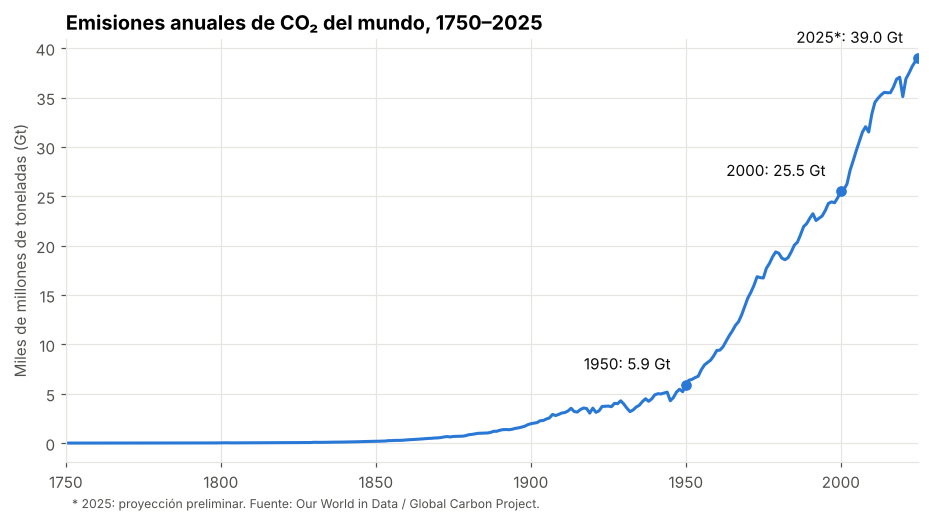

In [2]:
serie = mundo.dropna(subset=["co2"])
fig, ax = plt.subplots()
ax.plot(serie["year"], serie["co2"] / 1000, color=AZUL)
ax.set_title("Emisiones anuales de CO₂ del mundo, 1750–2025")
ax.set_ylabel("Miles de millones de toneladas (Gt)")
ax.set_xlim(1750, 2025)
for anio, texto in [(1950, "1950"), (2000, "2000"), (2025, "2025*")]:
    valor = serie.loc[serie["year"] == anio, "co2"].item() / 1000
    ax.annotate(f"{texto}: {valor:.1f} Gt", (anio, valor), textcoords="offset points",
                xytext=(-10, 10), ha="right", color=TEXTO)
    ax.plot(anio, valor, "o", color=AZUL, markersize=6)
ax.text(1752, -0.08, "* 2025: proyección preliminar. Fuente: Our World in Data / Global Carbon Project.",
        transform=ax.get_xaxis_transform(), color=TEXTO_2, fontsize=8, va="top")
plt.show()

e1950 = serie.loc[serie["year"] == 1950, "co2"].item()
e2024 = serie.loc[serie["year"] == ANIO, "co2"].item()
print(f"En {ANIO} el mundo emitió {e2024/1000:.1f} Gt, {e2024/e1950:.1f} veces lo de 1950.")

**Interpretación.** Hasta mediados del siglo XIX las emisiones eran prácticamente nulas. Empiezan a subir con la industrialización y se aceleran mucho después de 1950: en 2024 el mundo emitió **38,6 Gt de CO₂, 6,5 veces lo de 1950**. La proyección para 2025 (39,0 Gt) indica que las emisiones globales **todavía no han dejado de crecer**, aunque lo hacen más despacio que entre 1950 y 2010. Es la misma tendencia que describe el artículo en su sección sobre las emisiones globales.

## 3. Emisiones por persona en el mundo

Las emisiones totales crecen tanto por el aumento de la población como por el de las emisiones de cada persona. Para separar los dos efectos se grafica el promedio mundial **por persona**.

,t CO₂ por persona,población (miles de millones)
year,,
1950,2.376,2.49
1979,4.434,4.37
2000,4.133,6.17
2011,4.853,7.11
2020,4.450,7.89
2024,4.735,8.16


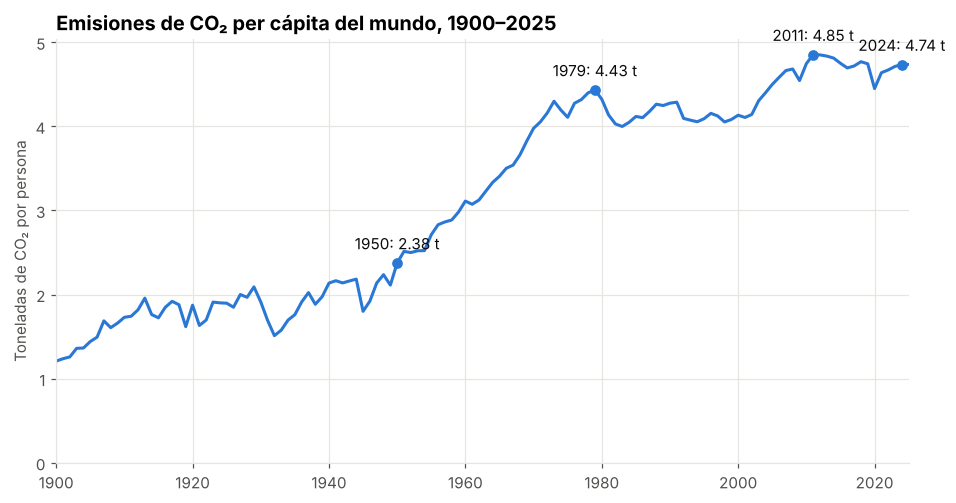

In [3]:
serie_pc = mundo.dropna(subset=["co2_per_capita"])
serie_pc = serie_pc[serie_pc["year"] >= 1900]
fig, ax = plt.subplots()
ax.plot(serie_pc["year"], serie_pc["co2_per_capita"], color=AZUL)
ax.set_title("Emisiones de CO₂ per cápita del mundo, 1900–2025")
ax.set_ylabel("Toneladas de CO₂ por persona")
ax.set_ylim(0, None)
ax.set_xlim(1900, 2025)
for anio in [1950, 1979, 2011, ANIO]:
    v = serie_pc.loc[serie_pc["year"] == anio, "co2_per_capita"].item()
    ax.plot(anio, v, "o", color=AZUL, markersize=6)
    ax.annotate(f"{anio}: {v:.2f} t", (anio, v), textcoords="offset points", xytext=(0, 9),
                ha="center", color=TEXTO)
plt.show()

tabla = serie_pc.set_index("year").loc[[1950, 1979, 2000, 2011, 2020, ANIO], ["co2_per_capita", "population"]]
tabla["population"] = (tabla["population"] / 1e9).round(2)
display(tabla.rename(columns={"co2_per_capita": "t CO₂ por persona", "population": "población (miles de millones)"}))

**Interpretación.** La historia por persona es distinta a la del total. Las emisiones per cápita se duplicaron entre 1950 (2,38 t) y 1979 (4,43 t), y desde entonces se han movido en una franja estrecha, entre 4 y 4,9 toneladas. El máximo fue en 2011 (4,85 t) y en 2024 el valor fue de 4,74 t.

En el mismo periodo la población mundial pasó de 4 370 millones (1979) a 8 160 millones (2024). Es decir: **desde finales de los años setenta, el aumento de las emisiones totales se explica sobre todo por el crecimiento de la población**, no porque cada persona emita más. Esto justifica analizar los datos per cápita, como propone la sección elegida del artículo.

## 4. Los países con mayores emisiones per cápita

El artículo señala que los mayores emisores por persona son productores de petróleo de Oriente Medio, y que Estados Unidos, Australia y Canadá emiten alrededor de tres veces el promedio mundial. Se ordenan los 15 países con más emisiones per cápita en 2024 y se marca el promedio mundial como referencia.

United States: 14.2 t por persona = 3.0 veces el promedio mundial
Australia: 14.4 t por persona = 3.0 veces el promedio mundial
Canada: 13.6 t por persona = 2.9 veces el promedio mundial


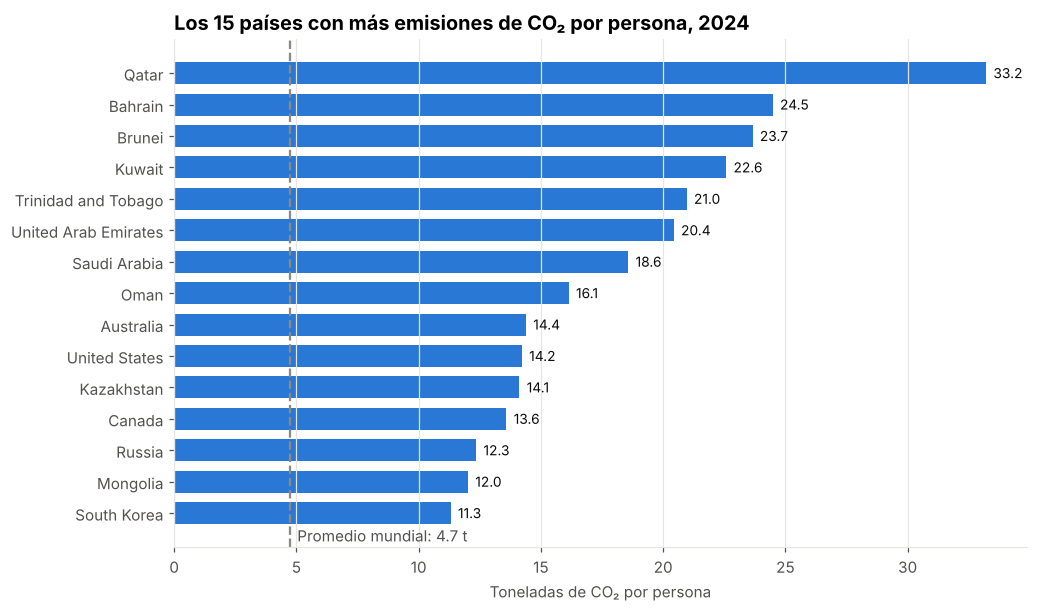

In [4]:
top = (paises[paises["year"] == ANIO]
       .nlargest(15, "co2_per_capita")
       .sort_values("co2_per_capita"))
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top["country"], top["co2_per_capita"], color=AZUL, height=0.7)
ax.axvline(promedio_mundial, color=GRIS, linestyle="--", linewidth=1.5)
ax.text(promedio_mundial + 0.3, -0.9, f"Promedio mundial: {promedio_mundial:.1f} t", color=TEXTO_2)
for y, v in enumerate(top["co2_per_capita"]):
    ax.text(v + 0.3, y, f"{v:.1f}", va="center", color=TEXTO, fontsize=9)
ax.set_title(f"Los 15 países con más emisiones de CO₂ por persona, {ANIO}")
ax.set_xlabel("Toneladas de CO₂ por persona")
ax.grid(axis="y", visible=False)
plt.show()

for pais in ["United States", "Australia", "Canada"]:
    v = paises.loc[(paises["country"] == pais) & (paises["year"] == ANIO), "co2_per_capita"].item()
    print(f"{pais}: {v:.1f} t por persona = {v / promedio_mundial:.1f} veces el promedio mundial")

**Interpretación.** Los ocho primeros lugares son productores de petróleo y gas: Qatar encabeza la lista con **33,2 t por persona, unas 7 veces el promedio mundial**, seguido de Baréin, Brunéi, Kuwait, Trinidad y Tobago, Emiratos, Arabia Saudita y Omán. Esto coincide con lo que dice el artículo.

El dato del artículo sobre Estados Unidos, Australia y Canadá se confirma con exactitud: los tres emiten **2,9 a 3,0 veces el promedio mundial**. Les siguen Kazajistán, Rusia y Mongolia, economías que dependen mucho del carbón y del gas, y Corea del Sur, con una industria pesada intensiva en energía.

## 5. Desigualdad entre grupos de ingreso

Los datos incluyen los cuatro grupos de ingreso del Banco Mundial. Esta gráfica compara la evolución de las emisiones por persona en cada grupo.

,t por persona,veces el ingreso bajo
country,,
Ingreso alto,9.73,34.8
Ingreso medio-alto,6.12,21.9
Ingreso medio-bajo,1.58,5.6
Ingreso bajo,0.28,1.0


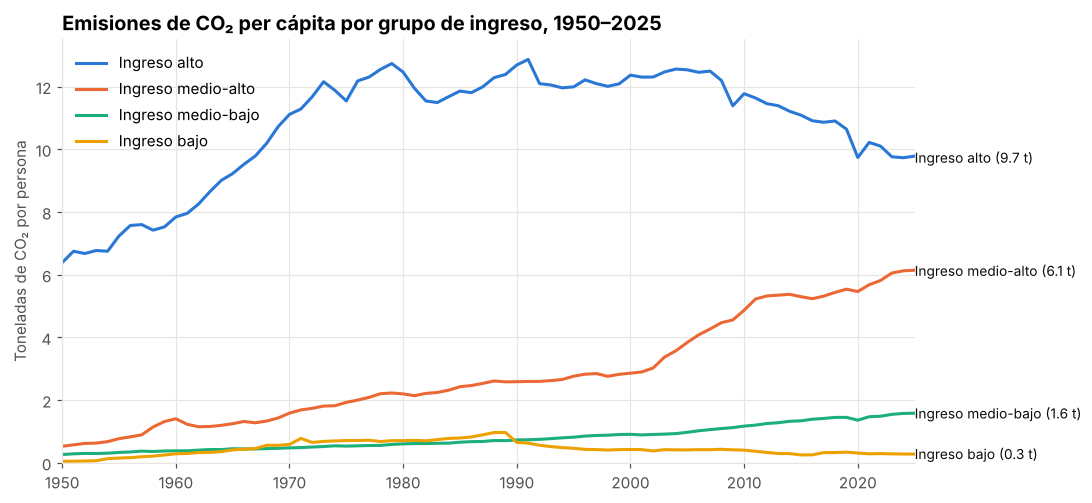

In [5]:
ETIQUETAS = {"High-income countries": "Ingreso alto",
             "Upper-middle-income countries": "Ingreso medio-alto",
             "Lower-middle-income countries": "Ingreso medio-bajo",
             "Low-income countries": "Ingreso bajo"}
COLORES = {"High-income countries": AZUL, "Upper-middle-income countries": NARANJA,
           "Lower-middle-income countries": VERDE, "Low-income countries": AMARILLO}
g = grupos[grupos["year"] >= 1950].dropna(subset=["co2_per_capita"])

fig, ax = plt.subplots()
for grupo, color in COLORES.items():
    d = g[g["country"] == grupo]
    ax.plot(d["year"], d["co2_per_capita"], color=color, label=ETIQUETAS[grupo])
    ultimo = d[d["year"] == ANIO]["co2_per_capita"].item()
    ax.text(ANIO + 1, ultimo, f"{ETIQUETAS[grupo]} ({ultimo:.1f} t)", va="center", color=TEXTO, fontsize=9)
ax.set_title("Emisiones de CO₂ per cápita por grupo de ingreso, 1950–2025")
ax.set_ylabel("Toneladas de CO₂ por persona")
ax.set_xlim(1950, 2025)
ax.set_ylim(0, None)
ax.legend(loc="upper left")
plt.show()

tabla = (g[g["year"] == ANIO].set_index("country")["co2_per_capita"]
         .rename(index=ETIQUETAS).loc[list(ETIQUETAS.values())].round(2).to_frame("t por persona"))
tabla["veces el ingreso bajo"] = (tabla["t por persona"] / tabla.loc["Ingreso bajo", "t por persona"]).round(1)
display(tabla)

**Interpretación.** La desigualdad es enorme: una persona en un país de **ingreso alto emitió 9,7 t en 2024, unas 35 veces más que una persona en un país de ingreso bajo (0,28 t)**. Las tendencias también son diferentes:

- **Ingreso alto:** se mantuvo cerca de 12–13 t desde finales de los años setenta hasta mediados de los 2000, y desde entonces baja. En 2024 está en 9,7 t, el nivel de finales de los años sesenta.
- **Ingreso medio-alto:** es el grupo que más creció desde el año 2000 (de unas 3 t a 6,1 t), impulsado sobre todo por China.
- **Ingreso medio-bajo y bajo:** han crecido muy poco y siguen por debajo de 2 t y de 0,5 t por persona.

Que el orden de las cuatro líneas siga exactamente el orden del ingreso es una primera evidencia de la relación ingreso–emisiones que se modela en el notebook 3.